In [12]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/E0.csv")

print(df.head())
print(df.shape)
print(df.columns)
print(df.info())

  Div        Date   Time    HomeTeam     AwayTeam  FTHG  FTAG FTR  HTHG  HTAG  \
0  E0  16/08/2024  20:00  Man United       Fulham     1     0   H     0     0   
1  E0  17/08/2024  12:30     Ipswich    Liverpool     0     2   A     0     0   
2  E0  17/08/2024  15:00     Arsenal       Wolves     2     0   H     1     0   
3  E0  17/08/2024  15:00     Everton     Brighton     0     3   A     0     1   
4  E0  17/08/2024  15:00   Newcastle  Southampton     1     0   H     1     0   

   ... B365CAHH B365CAHA  PCAHH  PCAHA  MaxCAHH  MaxCAHA  AvgCAHH  AvgCAHA  \
0  ...     1.86     2.07   1.83   2.11     1.88     2.11     1.82     2.05   
1  ...     2.05     1.88   2.04   1.90     2.20     2.00     1.99     1.88   
2  ...     2.02     1.91   2.00   1.90     2.05     1.93     1.99     1.87   
3  ...     1.87     2.06   1.86   2.07     1.92     2.10     1.83     2.04   
4  ...     1.87     2.06   1.88   2.06     1.89     2.10     1.82     2.05   

   BFECAHH  BFECAHA  
0     1.90     2.08  


In [13]:
home_wins = (df["FTR"] == "H").mean()
draws = (df["FTR"] == "D").mean()
away_wins = (df["FTR"] == "A").mean()

print("Home win percentage:", home_wins * 100)
print("Draw percentage:", draws * 100)
print("Away win percentage:", away_wins * 100)

Home win percentage: 40.78947368421053
Draw percentage: 24.47368421052632
Away win percentage: 34.73684210526316


Home teams win more often than Away teams.

In [14]:
print("Average home goals:", df["FTHG"].mean())
print("Average away goals:", df["FTAG"].mean())

Average home goals: 1.513157894736842
Average away goals: 1.4210526315789473


Home teams score approximately 0.09 more goals per match.

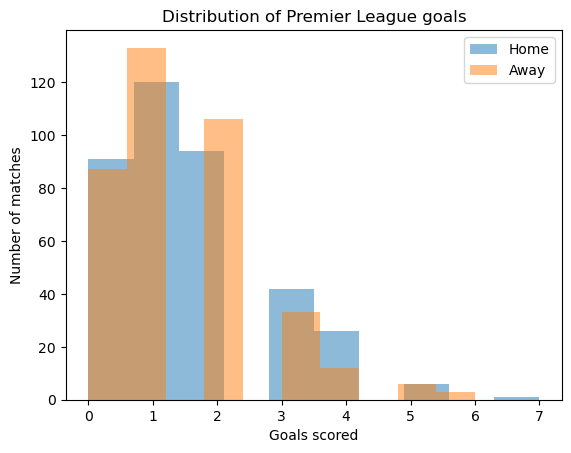

In [15]:
plt.hist(df["FTHG"].dropna(), alpha=0.5, label="Home")
plt.hist(df["FTAG"].dropna(), alpha=0.5, label="Away")

plt.xlabel("Goals scored")
plt.ylabel("Number of matches")
plt.title("Distribution of Premier League goals")
plt.legend()
plt.show()

Most teams score 1 or 2 goals. Zero goals are relatively common and high goal totals are relatively rare. This is what we might expect from a Poisson distribution. Let's compare probabilities predicted by the Poisson distribution against the actual frequencies in the dataset. Investigate expected outcomes and variance for Home and Away.

In [19]:
print("Home mean:", df["FTHG"].mean())
print("Home variance:", df["FTHG"].var())

print("Away mean:", df["FTAG"].mean())
print("Away variance:", df["FTAG"].var())

Home mean: 1.513157894736842
Home variance: 1.633071795583943
Away mean: 1.4210526315789473
Away variance: 1.4159144563255115


Home: variance is approximately 7.9% higher than the mean. Away: variance is approximately 0.4% lower than the mean. This is encouraging evidence for a Poisson model as we would expect EV and Var to be theoretically equal.

In [16]:
print("Home goal probabilities:")
print(df["FTHG"].value_counts(normalize=True).sort_index())

print("\nAway goal probabilities:")
print(df["FTAG"].value_counts(normalize=True).sort_index())

Home goal probabilities:
FTHG
0    0.239474
1    0.315789
2    0.247368
3    0.110526
4    0.068421
5    0.015789
7    0.002632
Name: proportion, dtype: float64

Away goal probabilities:
FTAG
0    0.228947
1    0.350000
2    0.278947
3    0.086842
4    0.031579
5    0.015789
6    0.007895
Name: proportion, dtype: float64


In [17]:
from scipy.stats import poisson
import numpy as np

home_lambda = df["FTHG"].mean()
away_lambda = df["FTAG"].mean()

goals = np.arange(0, 9)

home_predicted = poisson.pmf(goals, home_lambda)
away_predicted = poisson.pmf(goals, away_lambda)

print("Home predicted probabilities:")
print(home_predicted)

print("Away predicted probabilities:")
print(away_predicted)

Home predicted probabilities:
[2.20213468e-01 3.33217747e-01 2.52105533e-01 1.27158492e-01
 4.81027191e-02 1.45574018e-02 3.67127459e-03 7.93602589e-04
 1.50105753e-04]
Away predicted probabilities:
[2.41459715e-01 3.43126963e-01 2.43800737e-01 1.15484560e-01
 4.10274094e-02 1.16604216e-02 2.76167880e-03 5.60641561e-04
 9.95876458e-05]


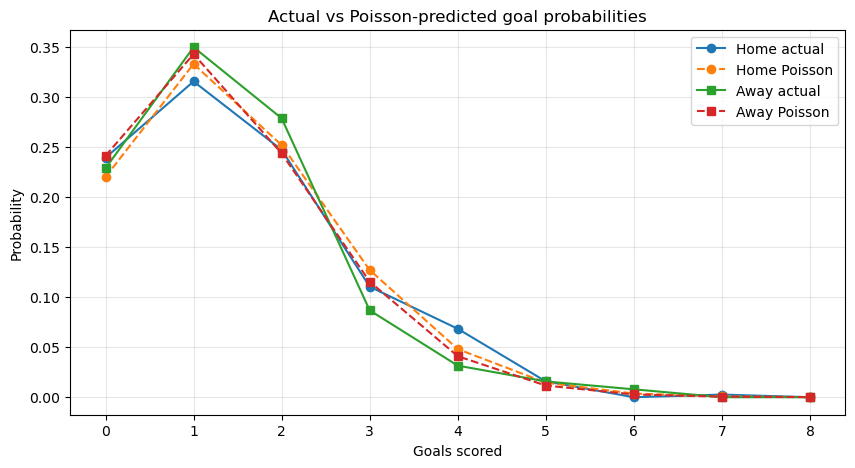

In [18]:
home_actual = df["FTHG"].value_counts(normalize=True).sort_index()
away_actual = df["FTAG"].value_counts(normalize=True).sort_index()

home_actual = home_actual.reindex(goals, fill_value=0)
away_actual = away_actual.reindex(goals, fill_value=0)

plt.figure(figsize=(10, 5))

plt.plot(goals, home_actual, "o-", label="Home actual")
plt.plot(goals, home_predicted, "o--", label="Home Poisson")

plt.plot(goals, away_actual, "s-", label="Away actual")
plt.plot(goals, away_predicted, "s--", label="Away Poisson")

plt.xlabel("Goals scored")
plt.ylabel("Probability")
plt.title("Actual vs Poisson-predicted goal probabilities")
plt.xticks(goals)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The overall shapes are quite similar, however, there are noticeable differences (particularly for away teams scoring two or three goals). A Poisson distribution captures the broad pattern of football scoring, but it doesn't perfectly reproduce the observed frequencies. Our next target is to perform a chi-squared goodness-of-fit test, as it will help us accurately determine whether the differences between the observed and Poisson-predicted frequencies are larger than we would reasonably expect from random variation.

In [20]:
from scipy.stats import chisquare, poisson
import numpy as np

def poisson_goodness_of_fit(data):
    lam = data.mean()

    observed = np.array([
        (data == 0).sum(),
        (data == 1).sum(),
        (data == 2).sum(),
        (data == 3).sum(),
        (data >= 4).sum()
    ])

    probabilities = [
        poisson.pmf(0, lam),
        poisson.pmf(1, lam),
        poisson.pmf(2, lam),
        poisson.pmf(3, lam),
        poisson.sf(3, lam)
    ]

    expected = np.array(probabilities) * len(data)

    statistic, p_value = chisquare(
        observed,
        expected,
        ddof=1
    )

    return statistic, p_value

print("Home:", poisson_goodness_of_fit(df["FTHG"]))
print("Away:", poisson_goodness_of_fit(df["FTAG"]))

Home: (np.float64(4.002119780948629), np.float64(0.26123532286350704))
Away: (np.float64(4.9286233959080405), np.float64(0.17709892434860455))


At 5% significance level: for both Home and Away cases, we fail to reject the null hypothesis that the observed goal frequencies follow the fitted Poisson distribution. Our next step is to use this to our advantage and build a predictive model of Home wins, draws and Away wins. We find the joint probability of every scoreline with Home and Away goals (follows Poisson and they are independent), then sum probabilities for each match outcome.

In [21]:
from scipy.stats import poisson
import numpy as np

home_lambda = df["FTHG"].mean()
away_lambda = df["FTAG"].mean()

goals = np.arange(0, 11)

home_probs = poisson.pmf(goals, home_lambda)
away_probs = poisson.pmf(goals, away_lambda)

# Joint probability of every scoreline
score_matrix = np.outer(home_probs, away_probs)

# Sum probabilities for each match outcome
home_win = np.tril(score_matrix, -1).sum()
draw = np.trace(score_matrix)
away_win = np.triu(score_matrix, 1).sum()

print("Home win:", home_win)
print("Draw:", draw)
print("Away win:", away_win)

Home win: 0.397543929817728
Draw: 0.24581090668744657
Away win: 0.3566442363007237


This is an extremely close match to the probabilities we calculated at the start! However, there is a major limitation, every fixture recieves the same predicted probabilities and we haven't considered factors such as: each team's attacking and defensive strength, home advantage and how recent performances affect expected goals. 